In [ ]:
#date ,plotly , object,preprocess date to date time,#check what can effect on my goal

In [1]:

import pandas as pd

In [2]:
pip install kaggle

Note: you may need to restart the kernel to use updated packages.


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kartik2112/fraud-detection")

print("Path to dataset files:", path)

ModuleNotFoundError: No module named 'kagglehub'

In [ ]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/fraud-detection/fraudTest.csv
/kaggle/input/fraud-detection/fraudTrain.csv


In [ ]:
df = pd.read_csv("/kaggle/input/fraud-detection/fraudTrain.csv")

In [ ]:
"""
Unnamed: 0: ده مجرد "ترقيم" تلقائي للصفوف

trans_date_trans_time: التاريخ والوقت اللي العملية تمت فيه بالظبط (سنة-شهر-يوم ساعة:دقيقة:ثانية).

cc_num: رقم بطاقة الائتمان (الفيزا) اللي اتعملت بيها العملية.

merchant: اسم المحل أو البراند اللي اتسحب منه الفلوس

category: نوع الحاجة اللي اشتراها).

amt: اختصار Amount، وده المبلغ اللي اتدفع في العملية.

first: الاسم الأول لصاحب الكارت.

last: اسم العائلة لصاحب الكارت.

gender: نوع صاحب الكارت (ذكر M أو أنثى F).

street: اسم الشارع اللي ساكن فيه صاحب الكارت.

city: المدينة اللي ساكن فيها صاحب الكارت.

state: الولاية أو المحافظة التابع ليها العميل.

zip: الرمز البريدي لمنطقة سكن العميل.

lat: خط العرض (Latitude) لعنوان سكن صاحب الكارت (موقعه على الخريطة).

long: خط الطول (Longitude) لعنوان سكن صاحب الكارت.

city_pop: عدد سكان المدينة اللي العميل ساكن فيها (الزحمة بتبين نمط الصرف).

job: وظيفة صاحب الكارت.

dob: تاريخ ميلاد صاحب الكارت (عشان تعرف سنه).

trans_num: رقم العملية (Transaction ID)، وده كود فريد لكل عملية بيطلع في الوصل.

unix_time: هو هو وقت العملية (رقم 2) بس بصيغة رقمية (بالثواني)، وده بيبقى سهل جداً لما تيجي تعمل حسابات برمجية.

merch_lat: خط العرض بتاع موقع "المحل" اللي العملية حصلت فيه.

merch_long: خط الطول بتاع موقع "المحل" اللي العملية حصلت فيه.

الهدف (The Target)

 is_fraud.

0: عملية طبيعية (صاحب الكارت هو اللي بيشتري).

1: عملية نصب (في حرامي سرق بيانات الكارت وبيصرف منها)."""

'\nUnnamed: 0: ده مجرد "ترقيم" تلقائي للصفوف\n\ntrans_date_trans_time: التاريخ والوقت اللي العملية تمت فيه بالظبط (سنة-شهر-يوم ساعة:دقيقة:ثانية).\n\ncc_num: رقم بطاقة الائتمان (الفيزا) اللي اتعملت بيها العملية.\n\nmerchant: اسم المحل أو البراند اللي اتسحب منه الفلوس\n\ncategory: نوع الحاجة اللي اشتراها).\n\namt: اختصار Amount، وده المبلغ اللي اتدفع في العملية.\n\nfirst: الاسم الأول لصاحب الكارت.\n\nlast: اسم العائلة لصاحب الكارت.\n\ngender: نوع صاحب الكارت (ذكر M أو أنثى F).\n\nstreet: اسم الشارع اللي ساكن فيه صاحب الكارت.\n\ncity: المدينة اللي ساكن فيها صاحب الكارت.\n\nstate: الولاية أو المحافظة التابع ليها العميل.\n\nzip: الرمز البريدي لمنطقة سكن العميل.\n\nlat: خط العرض (Latitude) لعنوان سكن صاحب الكارت (موقعه على الخريطة).\n\nlong: خط الطول (Longitude) لعنوان سكن صاحب الكارت.\n\ncity_pop: عدد سكان المدينة اللي العميل ساكن فيها (الزحمة بتبين نمط الصرف).\n\njob: وظيفة صاحب الكارت.\n\ndob: تاريخ ميلاد صاحب الكارت (عشان تعرف سنه).\n\ntrans_num: رقم العملية (Transaction ID)، وده كود فري

In [ ]:
# from my reserch
# amt =amount can impo,lat and long
"""

المبلغ (amt),الحرامي غالباً بيحاول يسحب مبالغ كبيرة بسرعة قبل ما الكارت يقفل، أو مبالغ غريبة مش متعود عليها صاحب الكارت.
المسافة الجغرافية,"دي أهم حاجة! لو بيت العميل في القاهرة (lat, long) والعملية بتحصل في محل بمطروح (merch_lat, merch_long) والفرق بينهم 10 دقائق.. أكيد ده مش صاحب الكارت، ده حرامي ""بيطير""!"
الوقت (trans_date_trans_time),لو العميل موظف وببيشتري دايماً الصبح، وفجأة حصلت عملية الساعة 4 الفجر؟ دي علامة استفهام كبيرة.
الفئة (category),"الحرامية بيميلوا يشتروا حاجات ""تتسيّل"" فلوس بسرعة (موبايلات، ذهب، إلكترونيات) مش هيروح يسرق الفيزا عشان يشتري خضار (grocery)."
سكان المدينة (city_pop),العمليات اللي بتحصل في مدن زحمة جداً بيبقى أسهل فيها التمويه، عكس القرى الصغيرة اللي بيبقى فيها نمط صرف ثابت.
عمر العميل (من dob),"لو صاحب الكارت راجل عجوز (80 سنة) وفجأة اشترى ""اشتراك ألعاب أونلاين"" أو ""لبس شبابي غالي""، ده نمط مش منطقي."""

'\n\nالمبلغ (amt),الحرامي غالباً بيحاول يسحب مبالغ كبيرة بسرعة قبل ما الكارت يقفل، أو مبالغ غريبة مش متعود عليها صاحب الكارت.\nالمسافة الجغرافية,"دي أهم حاجة! لو بيت العميل في القاهرة (lat, long) والعملية بتحصل في محل بمطروح (merch_lat, merch_long) والفرق بينهم 10 دقائق.. أكيد ده مش صاحب الكارت، ده حرامي ""بيطير""!"\nالوقت (trans_date_trans_time),لو العميل موظف وببيشتري دايماً الصبح، وفجأة حصلت عملية الساعة 4 الفجر؟ دي علامة استفهام كبيرة.\nالفئة (category),"الحرامية بيميلوا يشتروا حاجات ""تتسيّل"" فلوس بسرعة (موبايلات، ذهب، إلكترونيات) مش هيروح يسرق الفيزا عشان يشتري خضار (grocery)."\nسكان المدينة (city_pop),العمليات اللي بتحصل في مدن زحمة جداً بيبقى أسهل فيها التمويه، عكس القرى الصغيرة اللي بيبقى فيها نمط صرف ثابت.\nعمر العميل (من dob),"لو صاحب الكارت راجل عجوز (80 سنة) وفجأة اشترى ""اشتراك ألعاب أونلاين"" أو ""لبس شبابي غالي""، ده نمط مش منطقي.'

In [ ]:
df #cc_num and merchant check can be impo ,not impo Unnamed

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,1296670,2020-06-21 12:12:08,30263540414123,fraud_Reichel Inc,entertainment,15.56,Erik,Patterson,M,162 Jessica Row Apt. 072,...,37.7175,-112.4777,258,Geoscientist,1961-11-24,440b587732da4dc1a6395aba5fb41669,1371816728,36.841266,-111.690765,0
1296671,1296671,2020-06-21 12:12:19,6011149206456997,fraud_Abernathy and Sons,food_dining,51.70,Jeffrey,White,M,8617 Holmes Terrace Suite 651,...,39.2667,-77.5101,100,"Production assistant, television",1979-12-11,278000d2e0d2277d1de2f890067dcc0a,1371816739,38.906881,-78.246528,0
1296672,1296672,2020-06-21 12:12:32,3514865930894695,fraud_Stiedemann Ltd,food_dining,105.93,Christopher,Castaneda,M,1632 Cohen Drive Suite 639,...,32.9396,-105.8189,899,Naval architect,1967-08-30,483f52fe67fabef353d552c1e662974c,1371816752,33.619513,-105.130529,0
1296673,1296673,2020-06-21 12:13:36,2720012583106919,"fraud_Reinger, Weissnat and Strosin",food_dining,74.90,Joseph,Murray,M,42933 Ryan Underpass,...,43.3526,-102.5411,1126,Volunteer coordinator,1980-08-18,d667cdcbadaaed3da3f4020e83591c83,1371816816,42.788940,-103.241160,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe() #have negtive in data is normal? in long ,merch long

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


In [ ]:


df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])


df['dob'] = pd.to_datetime(df['dob'])


print(df[['trans_date_trans_time', 'dob']].dtypes)

trans_date_trans_time    datetime64[ns]
dob                      datetime64[ns]
dtype: object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   Unnamed: 0             1296675 non-null  int64         
 1   trans_date_trans_time  1296675 non-null  datetime64[ns]
 2   cc_num                 1296675 non-null  int64         
 3   merchant               1296675 non-null  object        
 4   category               1296675 non-null  object        
 5   amt                    1296675 non-null  float64       
 6   first                  1296675 non-null  object        
 7   last                   1296675 non-null  object        
 8   gender                 1296675 non-null  object        
 9   street                 1296675 non-null  object        
 10  city                   1296675 non-null  object        
 11  state                  1296675 non-null  object        
 12  zip                    12966

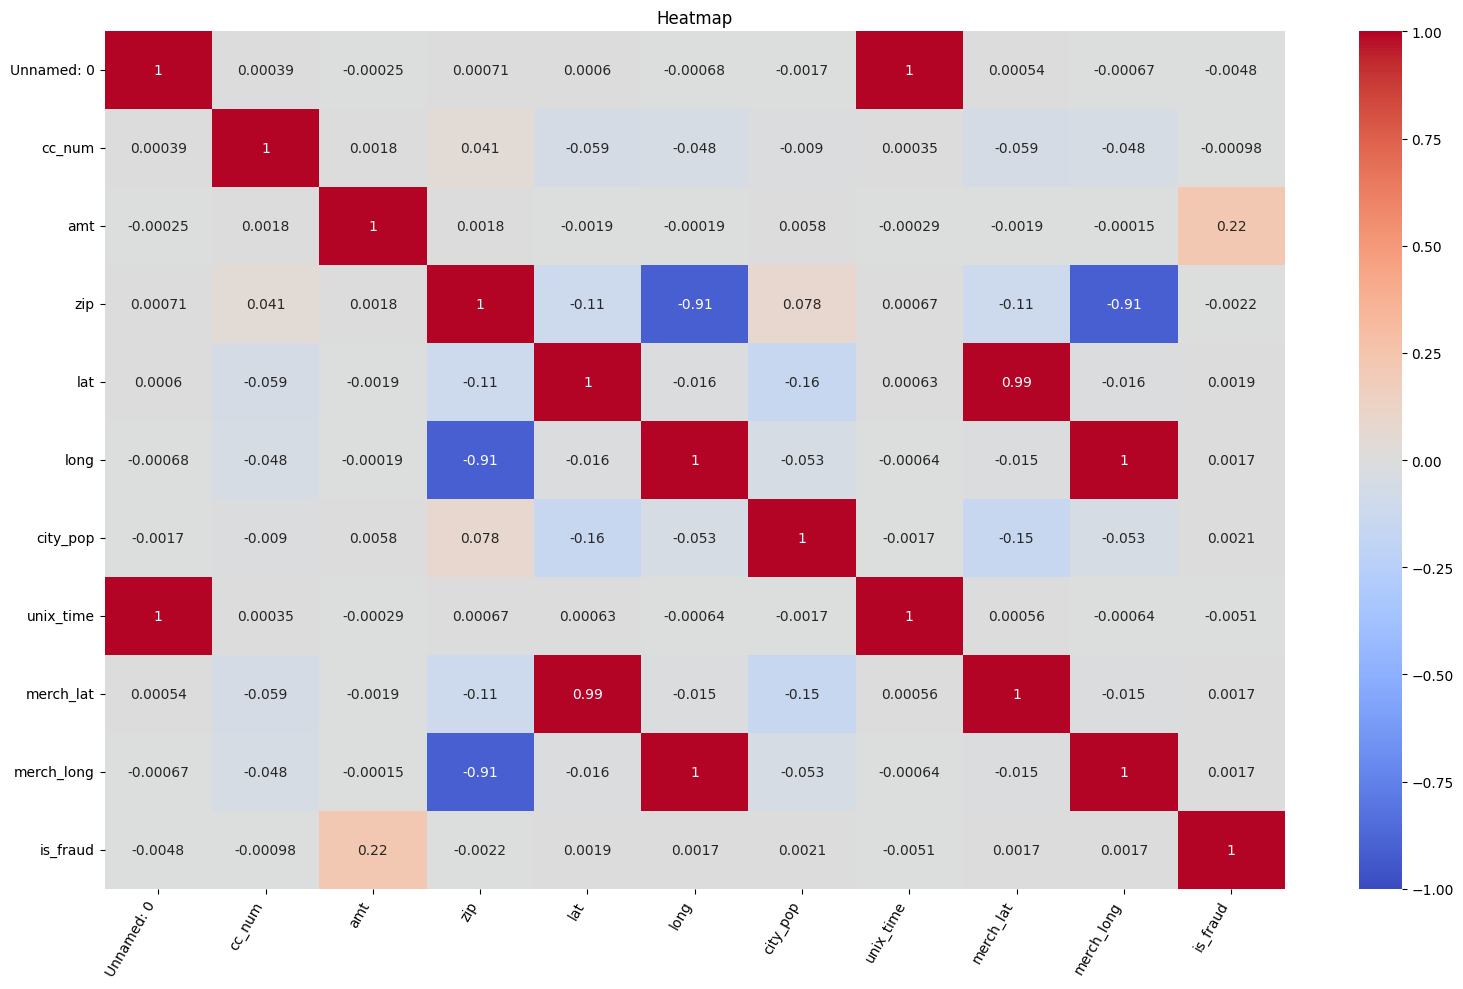

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
correlation_matrix = df.corr(numeric_only=True)


plt.figure(figsize=(16, 10))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0) #gpt
plt.title("Heatmap")
plt.xticks(rotation=60, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("heatmap.png", dpi=300, bbox_inches="tight")
plt.show()# long and merch long is same ,lat and merch lat
#zip with mersh long and long

In [ ]:
import pandas as pd
import numpy as np


cols_to_fix = df.select_dtypes(include=[np.number]).columns.tolist()
if 'is_fraud' in cols_to_fix:
    cols_to_fix.remove('is_fraud')


for col in cols_to_fix:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR


    df[col] = np.where(df[col] < lower_limit, lower_limit,
                       np.where(df[col] > upper_limit, upper_limit, df[col]))

print("تم ضبط الـ Outliers بنجاح لكل الأعمدة ما عدا is_fraud")

تم ضبط الـ Outliers بنجاح لكل الأعمدة ما عدا is_fraud


In [ ]:
df["is_fraud"].value_counts()

,count
is_fraud,
0,1289169
1,7506


In [ ]:
df.describe()

,Unnamed: 0,trans_date_trans_time,cc_num,amt,zip,lat,long,city_pop,dob,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1296675,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1296675,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,2019-10-03 12:47:28.070214144,3.204070e+15,5.786954e+01,4.880067e+04,3.852495e+01,-9.005769e+01,1.356506e+04,1973-10-03 19:02:55.017178512,1.349244e+09,3.852498e+01,-9.006053e+01,5.788652e-03
min,0.000000e+00,2019-01-01 00:00:18,6.041621e+10,1.000000e+00,1.257000e+03,2.364065e+01,-1.217580e+02,2.300000e+01,1924-10-30 00:00:00,1.325376e+09,2.389818e+01,-1.218880e+02,0.000000e+00
25%,3.241685e+05,2019-06-03 19:12:22.500000,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1962-08-13 00:00:00,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,2019-10-03 07:35:47,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1975-11-30 00:00:00,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,2020-01-28 15:02:55.500000,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1987-02-22 00:00:00,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,2020-06-21 12:13:37,1.133557e+16,1.933750e+02,9.978300e+04,5.292025e+01,-6.795030e+01,4.970550e+04,2005-01-29 00:00:00,1.371817e+09,5.279255e+01,-6.695090e+01,1.000000e+00
std,3.743180e+05,NaN,3.332165e+15,5.313852e+01,2.689322e+04,4.971890e+00,1.317278e+01,1.916111e+04,NaN,1.284128e+07,5.003970e+00,1.319147e+01,7.586269e-02


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import numpy as np

object_cols = df.select_dtypes(include=['object']).columns


le = LabelEncoder()
for col in object_cols:
    df[col] = le.fit_transform(df[col].astype(str))

# Select only numerical columns for scaling, excluding datetime columns and the target 'is_fraud'.
# After label encoding, the original object columns are now numerical.
# datetime64[ns] columns are not considered np.number and will be excluded automatically.
numeric_cols_for_scaling = df.select_dtypes(include=np.number).columns.drop('is_fraud', errors='ignore')

scaler = MinMaxScaler()
df[numeric_cols_for_scaling] = scaler.fit_transform(df[numeric_cols_for_scaling])

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   Unnamed: 0             1296675 non-null  float64       
 1   trans_date_trans_time  1296675 non-null  datetime64[ns]
 2   cc_num                 1296675 non-null  float64       
 3   merchant               1296675 non-null  float64       
 4   category               1296675 non-null  float64       
 5   amt                    1296675 non-null  float64       
 6   first                  1296675 non-null  float64       
 7   last                   1296675 non-null  float64       
 8   gender                 1296675 non-null  float64       
 9   street                 1296675 non-null  float64       
 10  city                   1296675 non-null  float64       
 11  state                  1296675 non-null  float64       
 12  zip                    12966

In [ ]:
import plotly.express as px

fraud_counts = df['is_fraud'].value_counts().reset_index()
fraud_counts.columns = ['is_fraud', 'count']


fig = px.bar(fraud_counts,
             x='is_fraud',
             y='count',
             color='is_fraud', # عشان يدي لون مختلف لكل عمود
             color_continuous_scale='RdBu_r', # تدرج ألوان مناسب للـ Fraud
             title="Distribution of Fraud Cases (Interactive)",
             labels={'is_fraud': 'Fraud (0: No, 1: Yes)', 'count': 'Number of Transactions'},
             text_auto=True) # بيكتب الرقم فوق العمود تلقائياً


fig.update_layout(xaxis_tickformat='d')

fig.show()